# Stage 2: Letting an LLM Find New Factors

**PG-S2-36 - Automatic Discovery of Interpretable Financial Factors**

Abu Wakkas Bastob

In Stage 1 I built 22 factors by hand and found that none of the models could predict Apple's next-day direction reliably.

Dr Liu's question for Stage 2 is: **can an LLM come up with factors on its own that do better than ours?**

To test this I built a loop that runs by itself. Claude suggests new factors, my code tests them, and the results go back to Claude so it can try again. This notebook walks through one run of 8 rounds.

In [1]:
# Section 1: Load the two runs (Claude and random)
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)

RUNS = sorted(Path('results/stage2/runs').glob('*'))
LLM_RUN = [r for r in RUNS if r.name.endswith('_claude')][-1]      # latest Claude run
RANDOM_RUN = [r for r in RUNS if r.name.endswith('_random')][-1]   # latest random-formula run

def load(run):
    board = pd.read_csv(run / 'scoreboard.csv').fillna({'reason': '', 'parent': '', 'closest': ''})
    kept = json.loads((run / 'kept_factors.json').read_text())
    return board, kept

llm_board, llm_kept = load(LLM_RUN)
rnd_board, rnd_kept = load(RANDOM_RUN)
config = json.loads((LLM_RUN / 'config.json').read_text())
print('Claude run :', LLM_RUN.name, '| model:', config.get('model'), '| rounds:', llm_board['round'].max())
print('Random run :', RANDOM_RUN.name, '| rounds:', rnd_board['round'].max())

Claude run : 20261015_1635_claude | model: claude-sonnet-5-5 | rounds: 8
Random run : 20261015_1645_random | rounds: 8


## Step 2: How the Loop Works

Every round goes through the same five steps:

1. **Claude suggests 6 factors.** 3 are improvements on something that already worked, and 3 are completely new ideas.
2. **My code builds each factor** from the formula Claude wrote, using only past prices.
3. **I test each one.** I add it to the 22 Stage 1 factors, retrain the models, and check if the score on Q3 goes up, for each year from 2022 to 2025.
4. **I keep it or throw it away.** It has to help in at least 3 of the 4 years, and by more than random luck would.
5. **The results go back to Claude** in the next round, including what failed and why.

Nobody picks the factors by hand, and Q4 is never used during the loop. It is saved for the final test in Step 10.

## Step 3: Turning Claude's Formula into Numbers

Claude writes each factor as a formula. For example:

`subtract(pct_change(AAPL_Close, 5), pct_change(QQQ_Close, 5))`

means "Apple's 5-day return minus the market's 5-day return".

My code reads the formula, checks it only uses allowed data, and calculates it for every day.

Before trusting it, I checked two things:
* If I write my 22 Stage 1 factors as formulas, I get exactly the same numbers as in Stage 1.
* If I delete all the data after a certain day, that day's value doesn't change. So no factor can secretly use future prices.

In [2]:
# Section 3: Check that the formula code works properly
from src.features import build_stage1_features
from src.stage2.context import BASE_FORMULAS
from src.stage2.formula import evaluate, validate, wide_prices, FormulaError

raw = pd.read_csv('data/processed/aligned_daily_ohlcv_5y.csv')
prices = wide_prices(raw)
features = build_stage1_features(raw)
stage1 = features.set_index(pd.to_datetime(features['Date']))

# Check 1: rebuild my 22 Stage 1 factors from formulas
same = {name: np.allclose(evaluate(f, prices).reindex(stage1.index), stage1[name]) for name, f in BASE_FORMULAS.items()}
print(f'Check 1: {sum(same.values())} of {len(same)} Stage 1 factors match exactly')

# Check 2: cut the data at one day and make sure no factor changes
day = pd.Timestamp('2024-03-15')
formulas = llm_board.loc[llm_board.status != 'invalid', 'formula']
changed = sum(not np.isclose(evaluate(f, prices.loc[:day]).iloc[-1], evaluate(f, prices).loc[day], equal_nan=True)
              for f in formulas)
print(f'Check 2: {len(formulas)} Claude factors recalculated with data cut at {day.date()}: {changed} changed')

# Formulas that break the rules are refused
for bad in ['lag(AAPL_Close, -1)', 'AAPL_Close + QQQ_Close', 'pct_change(TSLA_Close, 1)']:
    try:
        validate(bad)
    except FormulaError as e:
        print(f'Refused  {bad:28} -> {e}')

Check 1: 22 of 22 Stage 1 factors match exactly
Check 2: 48 Claude factors recalculated with data cut at 2024-03-15: 0 changed
Refused  lag(AAPL_Close, -1)          -> lag: window must be one of (1, 2, 3, 5, 10, 20, 60)
Refused  AAPL_Close + QQQ_Close       -> only function calls, input names and numbers are allowed
Refused  pct_change(TSLA_Close, 1)    -> unknown input 'TSLA_Close'


## Step 4: What I Tell Claude

Each round Claude gets the same instructions, plus everything it has tried so far and how each one scored:
* What we are predicting, and which data it can use
* How each factor will be tested and the rule for keeping it
* My 22 existing factors, so it doesn't repeat them
* A short summary of each stock's yearly returns, only up to June 2025 so it learns nothing about the test periods

In [3]:
# Section 4: The instructions Claude got in the last round (beginning, then the results part)
last = llm_board['round'].max()
prompt = (LLM_RUN / f'round_{last:02d}_prompt.txt').read_text()
print(prompt[:1400])
print('\n.........\n')
start = prompt.index('SCOREBOARD OF EVERYTHING TRIED SO FAR')  # where the past results start
print(prompt[start:start + 1600])

ROUND 8

GOAL
Predict whether AAPL closes higher tomorrow than today (binary). A factor is computed after the close of day t.

DATA (daily, adjusted OHLCV, Sept 2021 - Dec 2025)
Inputs: AAPL_Open, AAPL_High, AAPL_Low, AAPL_Close, AAPL_Volume, QQQ_Open, QQQ_High, QQQ_Low, QQQ_Close, QQQ_Volume, MSFT_Open, MSFT_High, MSFT_Low, MSFT_Close, MSFT_Volume, NVDA_Open, NVDA_High, NVDA_Low, NVDA_Close, NVDA_Volume
Market summary up to 30 June 2025:
- AAPL: 2021: +17% (daily vol 1.5%), 2022: -28% (daily vol 2.2%), 2023: +55% (daily vol 1.3%), 2024: +36% (daily vol 1.4%), 2025: -16% (daily vol 2.6%)
- QQQ: 2021: +5% (daily vol 1.1%), 2022: -33% (daily vol 2.0%), 2023: +56% (daily vol 1.1%), 2024: +28% (daily vol 1.1%), 2025: +8% (daily vol 1.9%); daily-return correlation with AAPL 0.79
- MSFT: 2021: +12% (daily vol 1.4%), 2022: -28% (daily vol 2.2%), 2023: +58% (daily vol 1.6%), 2024: +15% (daily vol 1.3%), 2025: +19% (daily vol 1.9%); daily-return correlation with AAPL 0.66
- NVDA: 2021: +31% (da

## Step 5: What Claude Suggested

Before suggesting new factors, Claude writes a few lines about what it learned from the last round. These are its own words, unedited.

In [4]:
# Section 5: What Claude wrote each round, then its first 6 factors
for r in sorted(llm_board['round'].unique()):
    resp = json.loads((LLM_RUN / f'round_{r:02d}_response.json').read_text())
    print(f'Round {r}: {resp.get("reflection", "")}\n')

first = llm_board[llm_board['round'] == 1][['name', 'mode', 'formula', 'hypothesis']]
first

Round 1: First round, no scoreboard. Existing useful factors are volatility and MSFT/NVDA returns, so I'll try variants that normalise volatility and cross-stock moves, plus new families: gaps, intraday position, volume-price agreement, and vol regime.

Round 2: Round 1 showed near-copies of existing factors don't add value, and the volume/gap ideas were noise. MSFT_return_1d and volatility were the most useful existing ones, so I'll try lagged peer returns, cross-stock volatility ratios and longer-horizon regime variables, which are less collinear with the existing set.

Round 3: Nothing has been kept yet. Gains are small and noisy, and the best result was a cross-stock relative-momentum factor (NVDA 10d minus AAPL 10d, +0.005, 3/4 years). Pure AAPL lag and volatility-ratio variants failed. This round I will try more cross-stock catch-up and mean-reversion factors, volatility-level interactions for the MSFT signal, and volume and intraday ideas that differ from earlier attempts.

Roun

,name,mode,formula,hypothesis
0,vol_ratio_5_20,variant,"safe_divide(rolling_std(pct_change(AAPL_Close, 1), 5), rolling_std(pct_change(AAPL_Close, 1), 20))",Short-vs-long volatility ratio captures vol regime shifts that precede mean reversion or rebounds.
1,msft_return_zscore_20,variant,"zscore(pct_change(MSFT_Close, 1), 20)",MSFT move relative to its recent volatility is a cleaner lead signal for AAPL than the raw return.
2,aapl_cum20_vol_adj,variant,"safe_divide(pct_change(AAPL_Close, 20), rolling_std(pct_change(AAPL_Close, 1), 20))",Volatility-adjusted momentum is more stable across regimes than raw 20d return.
3,close_position_in_range,new,"safe_divide(subtract(AAPL_Close, AAPL_Low), subtract(AAPL_High, AAPL_Low))",Closing near the day's high or low indicates intraday buying/selling pressure that may continue or revert next day.
4,overnight_gap,new,"subtract(safe_divide(AAPL_Open, lag(AAPL_Close, 1)), 1)",Overnight gap reflects news sentiment and tends to partially reverse or continue the next day.
5,volume_price_agreement,new,"multiply(sign(pct_change(AAPL_Close, 1)), pct_change(AAPL_Volume, 1))","Price moves on rising volume are more informative than those on falling volume, giving continuation or exhaustion si..."


## Step 6: How Every Factor Scored

For every factor, in every year: train on Q1-Q2 with the 22 factors plus the new one, and score on Q3. Then compare with the 22 factors alone.

* **auc_gain**: how much the score went up (positive) or down (negative), averaged over the 4 years and both models
* **years**: in how many of the 4 years it helped
* **max_corr**: how similar it is to a factor I already have (0.9 or more means it is basically a copy)

In [5]:
# Section 6: Every factor Claude suggested and how it scored
show = llm_board.assign(years=llm_board.years_helped.astype(str) + '/4')[
    ['round', 'name', 'mode', 'auc_gain', 'years', 'max_corr', 'status', 'reason']]
print(llm_board.status.value_counts().to_string(), '\n')
show.sort_values(['status', 'auc_gain'], ascending=[True, False]).round(4)

status
rejected    47
kept         1 



,round,name,mode,auc_gain,years,max_corr,status,reason
22,4,nvda_range_vs_aapl_range,new,0.0123,3/4,0.1482,kept,
47,8,msft_nvda_close_position_diff,new,0.0107,2/4,0.3145,rejected,helped only 2/4 years
32,6,nvda_range_ratio_aapl,variant,0.0103,3/4,0.9041,rejected,near-copy of nvda_range_vs_aapl_range
23,4,qqq_volume_zscore_20,new,0.0097,2/4,0.4750,rejected,helped only 2/4 years; mean auc_gain below 0.01
17,3,nvda_volume_surge_vs_aapl,new,0.0090,2/4,0.4988,rejected,helped only 2/4 years; mean auc_gain below 0.01
26,5,nvda_range_vs_qqq_range_zscore,variant,0.0090,4/4,0.6482,rejected,mean auc_gain below 0.01
24,5,msft_range_vs_aapl_range,variant,0.0083,3/4,0.4574,rejected,mean auc_gain below 0.01
31,6,nvda_range_vs_msft_range,variant,0.0065,3/4,0.7932,rejected,mean auc_gain below 0.01
19,4,nvda_volume_zscore_5d_change,variant,0.0059,2/4,0.2247,rejected,helped only 2/4 years; mean auc_gain below 0.01
14,3,msft_return_2d_sum,variant,0.0052,2/4,0.6848,rejected,helped only 2/4 years; mean auc_gain below 0.01


**Reading this output**

* Claude suggested **48 factors** over 8 rounds, and every formula was valid.
* **47 were thrown away and 1 was kept.** Most only helped in 1 or 2 years, or the gain was too small to tell apart from luck.
* 4 were thrown away because they were almost the same as a factor I already had. For example, one was 0.95 similar to `MSFT_return_1d`.

## Step 7: Why the Keep Rule Is Strict

One quarter is only about 63 days, so some factors will look useful just by luck.

To see how much luck can do, I tested **32 fake factors made of random numbers**. They contain no information at all.
* If the rule was only "helps in 3 of 4 years", **6 of the 32** fake factors would pass.
* Also needing the average gain to be at least 0.01, only **1 of 32** passes.

So anything I keep has to beat what random numbers can do.

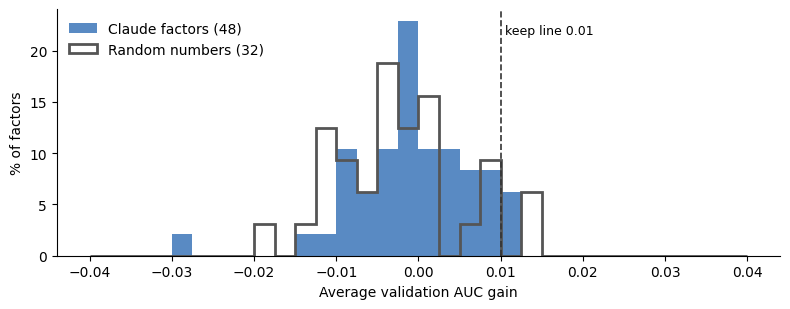

Random numbers above 0.01: 6% | Claude above 0.01: 6%


In [6]:
# Section 7: Claude's factors vs fake factors made of random numbers
noise = pd.read_csv('results/stage2/noise_null.csv')
scored = llm_board[llm_board.status != 'invalid']

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(-0.04, 0.04, 33)
ax.hist(scored.auc_gain.clip(-0.04, 0.04), bins=bins, weights=np.full(len(scored), 100 / len(scored)), color='#2f6db5', alpha=0.8, label=f'Claude factors ({len(scored)})')
ax.hist(noise.auc_gain, bins=bins, weights=np.full(len(noise), 100 / len(noise)), histtype='step', lw=2, color='#555', label='Random numbers (32)')
ax.axvline(0.01, color='#333', lw=1.2, ls='--')
ax.text(0.0105, ax.get_ylim()[1] * 0.9, 'keep line 0.01', fontsize=9)
ax.set_xlabel('Average validation AUC gain'); ax.set_ylabel('% of factors')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f'Random numbers above 0.01: {(noise.auc_gain >= 0.01).mean():.0%} | Claude above 0.01: {(scored.auc_gain >= 0.01).mean():.0%}')

**Reading this output**

* The blue bars (Claude's factors) and the grey outline (random numbers) sit mostly in the same place. Most single factors don't help much, which shows how hard this problem is.
* Only factors to the right of the dashed line can be kept. One of Claude's factors made it there and also helped in 3 of the 4 years.
* Without this rule, I would have kept factors that only looked good by luck.

## Step 8: Is Claude Better Than Random Guessing?

To be fair, I ran the exact same loop again, but this time the factors were random formulas instead of Claude's. Same number of rounds, same tests, same keep rule.

If Claude is actually useful, its factors should score better than the random ones.

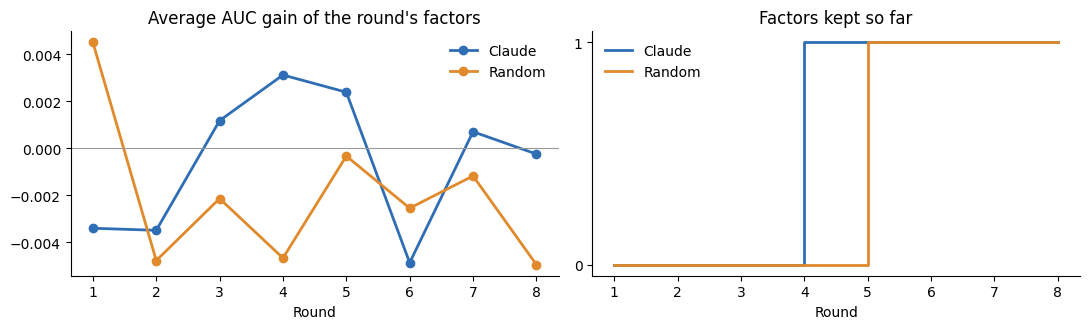

,Claude,Random
factors tried,48.0000,48.000
invalid formulas,0.0000,9.000
average AUC gain,-0.0006,-0.002
helped 3+ of 4 years,9.0000,8.000
kept,1.0000,1.000


In [7]:
# Section 8: Claude vs random formulas, round by round
def per_round(board):
    s = board[board.status != 'invalid']
    g = s.groupby('round').agg(mean_gain=('auc_gain', 'mean'), best_gain=('auc_gain', 'max'))
    g['kept_total'] = board.assign(k=board.status.eq('kept')).groupby('round').k.sum().cumsum()
    g['invalid'] = board.groupby('round').apply(lambda x: x.status.eq('invalid').sum())
    return g

llm_r, rnd_r = per_round(llm_board), per_round(rnd_board)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for g, name, col in [(llm_r, 'Claude', '#2f6db5'), (rnd_r, 'Random', '#e08a2b')]:
    axes[0].plot(g.index, g.mean_gain, marker='o', color=col, lw=2, label=name)
    axes[1].step(g.index, g.kept_total, where='post', color=col, lw=2, label=name)
axes[0].axhline(0, color='#999', lw=0.8)
axes[0].set_title('Average AUC gain of the round\'s factors'); axes[0].set_xlabel('Round')
axes[1].set_title('Factors kept so far'); axes[1].set_xlabel('Round')
from matplotlib.ticker import MaxNLocator
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    name: {'factors tried': len(b), 'invalid formulas': int(b.status.eq('invalid').sum()),
           'average AUC gain': round(b.loc[b.status != 'invalid', 'auc_gain'].mean(), 4),
           'helped 3+ of 4 years': int((b.years_helped >= 3).sum()),
           'kept': int(b.status.eq('kept').sum())}
    for name, b in [('Claude', llm_board), ('Random', rnd_board)]})
summary

**Reading this output**

* **Claude learns from the feedback.** Its average score went from negative in rounds 1-2 to positive in rounds 3-5. After it found the NVIDIA-vs-Apple range factor in round 4, it spent the next rounds trying versions of the same idea. One version helped in all 4 years but was just under the 0.01 line.
* **Claude's factors were a bit better on average** (-0.0006 vs -0.0020), and all of Claude's formulas worked, while 9 of the random ones broke.
* **Both runs kept 1 factor.** The random run got lucky once, which fits the fake-factor test from Step 7.
* So on Q3 alone, Claude is only slightly ahead. The real comparison is the final test in Step 10.

## Step 9: The Factor Claude Found

In [8]:
# Section 9: The kept factor, Claude's reason for it, and its score in each year
by_year = pd.read_csv(LLM_RUN / 'scores_by_year.csv')
if llm_kept:
    kept_names = [k['name'] for k in llm_kept]
    table = by_year[by_year.factor.isin(kept_names)].pivot_table(index='factor', columns='year', values='auc_gain').round(4)
    table['average'] = table.mean(axis=1).round(4)
    display(pd.DataFrame(llm_kept)[['name', 'round', 'formula', 'hypothesis']])
    display(table)
else:
    print('No Claude factor met the selection rule.')

,name,round,formula,hypothesis
0,nvda_range_vs_aapl_range,4,"subtract(safe_divide(subtract(NVDA_High, NVDA_Low), NVDA_Close), safe_divide(subtract(AAPL_High, AAPL_Low), AAPL_Clo...",Relative intraday turbulence in NVDA versus AAPL captures sector stress that AAPL has yet to absorb.


year,2022,2023,2024,2025,average
factor,,,,,
nvda_range_vs_aapl_range,-0.0061,0.0163,0.0087,0.0303,0.0123


**Reading this output**

* **`nvda_range_vs_aapl_range`** = how much NVIDIA moved between its daily high and low, minus how much Apple did (both as % of price).
* Claude's reasoning: when NVIDIA is much jumpier than Apple, something is happening in tech stocks that hasn't reached Apple yet.
* It helped in 2023, 2024 and 2025, and hurt a little in 2022.
* It is nothing like my 22 factors (only 0.15 similar), so it is new information, not a copy.

## Step 10: The Final Test on Q4

This is the first and only time Q4 is used. For each year I train on Q1-Q2 twice:
* with my 22 Stage 1 factors
* with the 22 factors plus the kept factor

Then I predict Q4 and run the same backtest as Stage 1 (hold Apple only on days the model says "up"). I do the same for the random run's factor so the comparison is fair.

In [9]:
# Section 10: Final test on Q4 (used only here)
from src.stage2.final_test import run_final_test

results = []
for name, kept in [('Claude', llm_kept), ('Random', rnd_kept)]:
    if kept:
        m, eq = run_final_test(features, prices, raw, kept)
        results.append(m.assign(source=name))
final = pd.concat(results, ignore_index=True) if results else pd.DataFrame()

if len(final):
    base = final[final.features == 'stage1_22'].drop_duplicates(['year', 'model']).assign(source='Stage 1 (22 factors)')
    plus = final[final.features == 'stage1_plus_llm'].assign(source=lambda d: d.source + ' factors added')
    view = pd.concat([base, plus])
    ba = view.pivot_table(index=['model', 'source'], columns='year', values='balanced_accuracy').round(3)
    ba['average'] = ba.mean(axis=1).round(3)
    ret = view.pivot_table(index=['model', 'source'], columns='year', values='strategy_return').round(3)
    ret.loc[('buy and hold', 'Apple'), :] = final.groupby('year').buy_hold_return.first().round(3)
    print('Test balanced accuracy (0.5 = coin flip)'); display(ba)
    print('Backtest return in Q4'); display(ret)

Test balanced accuracy (0.5 = coin flip)


year                                       2022   2023   2024   2025  average
model               source                                                   
logistic_regression Claude factors added  0.467  0.609  0.551  0.425    0.513
                    Random factors added  0.504  0.491  0.451  0.543    0.497
                    Stage 1 (22 factors)  0.459  0.473  0.451  0.411    0.448
random_forest       Claude factors added  0.533  0.559  0.476  0.432    0.500
                    Random factors added  0.488  0.505  0.502  0.454    0.487
                    Stage 1 (22 factors)  0.529  0.523  0.489  0.418    0.490

Backtest return in Q4


year                                       2022   2023   2024   2025
model               source                                          
logistic_regression Claude factors added -0.101  0.138  0.048 -0.001
                    Random factors added -0.091  0.031  0.021  0.062
                    Stage 1 (22 factors) -0.119  0.057  0.021 -0.006
random_forest       Claude factors added  0.147  0.066  0.011 -0.027
                    Random factors added  0.095  0.048  0.040 -0.019
                    Stage 1 (22 factors)  0.111  0.049  0.030 -0.032
buy and hold        Apple                -0.086  0.110  0.108  0.065

**Reading this output**

* **Logistic Regression:** adding Claude's factor raised the test score from **0.448 to 0.513** on average, and it was better in **all 4 years**. The random factor got 0.497.
* **Random Forest:** **0.490 to 0.500**, better in 3 of 4 years. The random factor made it slightly worse (0.487).
* **Backtest:** with Claude's factor, Logistic Regression made more money than the Stage 1 model in every year, and beat simply holding Apple in 2023 (+13.8% vs +11.0%).
* **To be careful:** this is one factor from one run, and each test quarter is only 63 days. 2025 is still below 0.5.

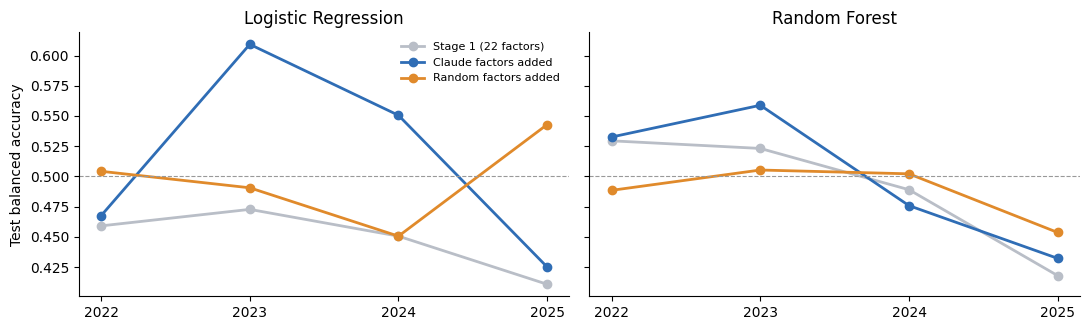

In [10]:
# Section 10b: Test score with and without the new factor
if len(final):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    for ax, model in zip(axes, ['logistic_regression', 'random_forest']):
        d = view[view.model == model]
        for src, col in [('Stage 1 (22 factors)', '#b9bec7'), ('Claude factors added', '#2f6db5'), ('Random factors added', '#e08a2b')]:
            s = d[d.source == src].sort_values('year')
            if len(s):
                ax.plot(s.year, s.balanced_accuracy, marker='o', lw=2, color=col, label=src)
        ax.axhline(0.5, color='#999', lw=0.8, ls='--')
        ax.set_title(model.replace('_', ' ').title()); ax.set_xticks([2022, 2023, 2024, 2025])
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('Test balanced accuracy'); axes[0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()

## Summary

**Can an LLM find factors that do better than mine?** From this first run, the answer is **yes, a little.**

* The loop runs completely on its own: Claude suggests, my code tests, and the results go back to Claude. 8 rounds and 48 factors cost well under US$1.
* It is safe: the formula code matches Stage 1 exactly, no factor can see the future, and Q4 was never touched during the loop.
* Claude did learn from the feedback. Once it found the NVIDIA-vs-Apple range idea, it kept building on it.
* On the final test, Claude's factor improved both models, and did better than the factor found by random guessing.

**What I can't claim yet:** it is only one factor from one run, most of Claude's ideas didn't help, and the improvement is small.

**Next steps:**
* Run the loop and the random version a few more times, to check Claude's lead isn't luck
* Run more rounds, and add each kept factor to the base set so the next ones have to beat it
* Give Claude more detail in the feedback, such as which years each factor failed in